# Voxelization

The statue comes as a 3D model, a mesh of triangles. Here we check the models, turn them into cubes (voxels) and see how much detail each cube size keeps.

## Setup

In [1]:
import logging
import warnings
from pathlib import Path

# A few docstrings in the toolbox trigger SyntaxWarnings when Python compiles them; not related to our code
warnings.filterwarnings("ignore", category=SyntaxWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spatialgeometry as sg
import spatialmath as sm
import swift
import trimesh
from sculptor.cell import Cell
from sculptor.model import (
    CUBE_SIZE,
    MODELS,
    STATUE_HEIGHT,
    Voxels,
    from_grid,
    grid_centers,
    inside,
    place,
    proxy_pawn,
    voxelize,drop_interior,
)
from sculptor.scene import MARBLE, RECORDINGS, STATUE, add_table, fix_mesh_paths, recording, show_gif
# The 3D models of the statues (the notebook runs from notebooks/)
MODELS = Path("..") / "models"

# The tip of the chisel is in models/ too, but it is not a statue
NOT_STATUES = {"chisel_tip.stl"}

# Colour of the statue cubes in the plots
STATUE_COLOR = "#b0b0b0"


# Closing a Swift window leaves a few websocket tasks pending; they are harmless
logging.getLogger("asyncio").setLevel(logging.CRITICAL)

# Without this, Swift on Windows cannot load any mesh (see sculptor/scene.py)
fix_mesh_paths()

# The Swift recordings are saved in results/recordings/; True records them again
RECORD = False

## 1. The models

A model can only be voxelized if it is closed (watertight); otherwise it has no clear inside. Files from 3D printing sites often have small gaps, so we count the open edges (edges of only one triangle, the borders of the holes) and the separate parts.

In [2]:
def check(mesh: trimesh.Trimesh) -> dict:
    """The numbers that say whether a model can be voxelized."""
    open_edges = trimesh.grouping.group_rows(mesh.edges_sorted, require_count=1)
    width, depth, height = mesh.extents
    return {"faces": len(mesh.faces),
            "parts": len(mesh.split(only_watertight=False)),
            "open edges": len(open_edges),
            "watertight": mesh.is_watertight,
            "size x y z": np.round(mesh.extents, 2),
            "height / width": round(height / max(width, depth), 2)}


files = sorted(f for f in MODELS.iterdir() if f.suffix in {".stl", ".obj"} and f.name not in NOT_STATUES)
meshes = {f.name: trimesh.load(f, force="mesh") for f in files}
pd.DataFrame({name: check(mesh) for name, mesh in meshes.items()}).T

,faces,parts,open edges,watertight,size x y z,height / width
Chess_Pawn.stl,2892,3,0,False,"[20.0, 20.0, 36.0]",1.8


**What the table shows**

- **Chess_Pawn.stl** has no holes (0 open edges) but is still not watertight. So some edges must be shared by three or more triangles. That fits the 3 parts: the pieces are separate shells that touch where they meet. It needs a fix before the inside can be filled reliably.

**Shape:** the pawn is tall and narrow, 1.8 times taller than it is wide.

**Suggested improvement later on** check whether each pawn part is watertight on its own. If so we have to voxelize them separately and combine the grids. This is  an improvemnt for the future TBD

The models as they are in the files, to check that they stand upright (z up).

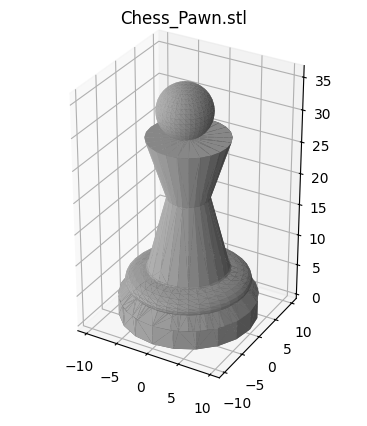

In [3]:
fig = plt.figure(figsize=(4 * len(meshes), 4))
for k, (name, mesh) in enumerate(meshes.items(), start=1):
    ax = fig.add_subplot(1, len(meshes), k, projection="3d")
    ax.plot_trisurf(*mesh.vertices.T, triangles=mesh.faces, color="#b0b0b0", linewidth=0)
    ax.set_aspect("equal")
    ax.set_title(name)
fig.tight_layout()
plt.show()

## 2. Repair

Three repairs fix most gaps: joining vertices that are at the same place up to rounding, turning the flipped triangles the right way, and filling small holes. The files are not changed here; we only look at whether the repair works.

In [4]:
def repair(mesh: trimesh.Trimesh) -> trimesh.Trimesh:
    """A repaired copy of the mesh."""
    mesh = mesh.copy()
    mesh.merge_vertices(digits_vertex=4)
    trimesh.repair.fix_normals(mesh)
    trimesh.repair.fill_holes(mesh)
    return mesh


repaired = {name: repair(mesh) for name, mesh in meshes.items()}
pd.DataFrame({name: check(mesh) for name, mesh in repaired.items()}).T

,faces,parts,open edges,watertight,size x y z,height / width
Chess_Pawn.stl,2892,11,0,False,"[20.0, 20.0, 36.0]",1.8


### What the tables show

The **pawn** has no open edges, so it has no holes, yet it is not watertight. A mesh is watertight when every edge is shared by exactly two triangles; with no open edges, the only way to fail is edges shared by *more* than two triangles. That happens where separate parts touch, and the pawn is made of 3 parts. The repair makes it worse (11 parts), so we keep the file as it is and look at its parts.

In [5]:
def edge_counts(mesh: trimesh.Trimesh) -> dict:
    """How many edges are shared by one, two, or more than two triangles."""
    shared_by = np.array([len(group) for group in trimesh.grouping.group_rows(mesh.edges_sorted)])
    return {"1 (open)": int((shared_by == 1).sum()),
            "2 (closed)": int((shared_by == 2).sum()),
            "more than 2": int((shared_by > 2).sum())}


pawn_file = meshes["Chess_Pawn.stl"]
parts = pawn_file.split(only_watertight=False)
print("Edges of the pawn shared by:", edge_counts(pawn_file))
pd.DataFrame({"faces": [len(part.faces) for part in parts],
              "watertight": [part.is_watertight for part in parts],
              "bottom [mm]": [round(part.bounds[0, 2], 1) for part in parts],
              "top [mm]": [round(part.bounds[1, 2], 1) for part in parts]},
             index=pd.RangeIndex(1, len(parts) + 1, name="part"))

Edges of the pawn shared by: {'1 (open)': 0, '2 (closed)': 4334, 'more than 2': 2}


,faces,watertight,bottom [mm],top [mm]
part,,,,
1,2888,True,0.0,36.0
2,2,True,7.3,7.4
3,2,True,7.3,7.4


If every part is watertight on its own, the pawn is just a few closed pieces that overlap, like a base, a body and a head glued together. Then we can still tell inside from outside: a point is inside the pawn when it is inside any of its parts (section 3.3).

## 3. Voxelize the pawn

The rest of the code never uses the mesh. The carving, the Swift scene and the evaluation all work on `Voxels` (in `sculptor/model.py`): the centres of the cubes of the block, in the block frame, and which of them belong to the statue. `voxelize` has to turn a mesh into that, in four steps:

1. **Scale and place** the mesh so it stands on the table, centred on its axis.
2. **Lay a grid** of cubes around it.
3. **Keep the cubes** whose centre is inside the mesh.
4. **Build the block** with `from_grid`, which adds the marble around the statue.

We write each step here first and look at the result. Once it works, the same code goes into `voxelize` in `model.py`, and the notebook will call that instead.

### 3.1 Scale and place

The models come in millimetres and at any position. In the block frame the statue has to be `STATUE_HEIGHT` tall, stand on the table (its lowest point at $z = 0$), and be centred on the axis of the table, so it turns in place when the table turns.

So we scale the mesh by

$$s = \frac{h}{z_{max} - z_{min}}$$

where $h$ is the height we want, and then move it so the centre of its bounding box is at $x = y = 0$ and its base at $z = 0$.

In [6]:

pawn = place(pawn_file, STATUE_HEIGHT)
pd.DataFrame(pawn.bounds.round(4), index=["min", "max"], columns=["x [m]", "y [m]", "z [m]"])

,x [m],y [m],z [m]
min,-0.1167,-0.1167,0.00
max,0.1167,0.1167,0.42


The pawn now goes from $z = 0$ to $z = 0.42$ m, and from $-x_{max}$ to $+x_{max}$ across, the same on both sides of the axis.

### 3.2 The grid of cubes

Each cube has a side $a$ = `CUBE_SIZE` (0.03 m, chosen in notebook 00). The layers sit on the table, so layer $k$ has its centre at

$$z_k = \left(k + \tfrac{1}{2}\right) a, \qquad k = 0, \dots, n_z - 1, \qquad n_z = \frac{h}{a} = \frac{0.42}{0.03} = 14$$

Across, we take an **odd** number of cubes, as `proxy_pawn` does, so one column of cubes sits exactly on the axis of the table and the grid is symmetric. We take enough of them to cover the widest part of the statue.

In [7]:

centers = grid_centers(pawn, CUBE_SIZE)
print(f"Grid of {centers.shape[0]} x {centers.shape[1]} x {centers.shape[2]} = {np.prod(centers.shape[:3])} cubes")

Grid of 9 x 9 x 14 = 1134 cubes


**How `grid_centers` works**
- `half = ceil(max|bounds| / size)`: cubes from the axis to the side, $\lceil 0.117/0.03 \rceil = 4$
- `arange(-half, half + 1) * size`: 9 centres, $-0.12, \dots, 0, \dots, 0.12$ m (odd count, one on the axis)
- `(arange(14) + 0.5) * size`: layer centres $z_k = (k + \tfrac12)\,a$
- `meshgrid` + `stack`: every $(x, y, z)$ combination, shape $(9, 9, 14, 3)$

**How many cubes across?** After `place`, the pawn reaches $r = 0.117$ m from the axis. A cube counts as statue only if its **centre** is inside the mesh, so the outermost centre, $m$ steps from the axis, must reach the edge:
$$m\,a \ge r \;\Rightarrow\; m = \left\lceil \tfrac{0.117}{0.03} \right\rceil = \lceil 3.89 \rceil = 4, \qquad n = 2m + 1 = 9$$
The count is odd, so one column sits on the axis. With $n_z = 0.42/0.03 = 14$ layers, that gives $9 \times 9 \times 14 = 1134$ cubes ($11 \times 11 \times 15$ after `from_grid` adds the marble layer).

### 3.3 Which cubes are inside

A cube belongs to the statue when its **centre** is inside the mesh. `trimesh` tests a point by casting a ray from it and counting how many times the ray crosses the surface: an odd number means inside, an even number outside. This only makes sense on a closed surface, and the pawn as a whole is not one. So, as seen in section 2, we test each part on its own and keep a cube when it is inside **any** part.

Testing the centre means that, roughly, a cube is kept when at least half of it is inside the statue. Thin details, narrower than a cube, can fall between two centres and disappear; section 4 measures how much of the model is lost this way for each cube size.

A cube belongs to the statue when its **centre** is inside the mesh. To test this, we send a vertical ray up through each column of cubes and find the heights where it crosses the surface of the mesh. A point is inside when the ray crosses the surface an **odd** number of times above it: once to get out of a simple shape, three times if it goes out, back in, and out again. One ray per column answers all 14 cubes of that column at once.

Two details make this work on our models:

- **Parts.** The parity rule only holds for a closed surface, and the pawn as a whole is not one. So each part is tested on its own, and a cube is statue when it is inside **any** part.
- **A tiny shift.** A ray that runs exactly along an edge, or through a vertex (like the tip of the pawn, right on the axis), touches two triangles at the same point and counts the crossing twice. Shifting all rays sideways by a few micrometres avoids that, and it changes nothing next to a 3 cm cube.

Testing the centre means that, roughly, a cube is kept when at least half of it is inside the statue. Thin details, narrower than a cube, can fall between two centres and disappear; section 4 measures how much of the model is lost this way for each cube size.

In [8]:


statue = inside(pawn, centers)
print(f"{statue.sum()} of {statue.size} cubes are inside the pawn")

208 of 1134 cubes are inside the pawn


To find where the ray crosses one triangle (`crossings`), we look at the triangle from above and ask trimesh for the **barycentric weights** $w_a, w_b, w_c$ of the ray's point $(x, y)$: how much of each corner the point is made of, with $w_a + w_b + w_c = 1$. The point is inside the triangle when all three weights are $\ge 0$, and the ray then crosses it at the same mix of the corners' heights:

$$z = w_a\,a_z + w_b\,b_z + w_c\,c_z$$

### 3.4 The block

`from_grid` (already in `model.py`) takes this grid of True and False, adds one layer of marble around the statue on the sides and on top (not below: that is the table), and returns the `Voxels` the rest of the code uses. `Voxels` checks itself when it is built, so a wrong grid fails right here, for example if no cube is statue, or if the block does not sit on $z = 0$.

In [9]:
voxels = from_grid(statue, CUBE_SIZE)
print(f"{len(voxels.centers)} cubes in the block: "
      f"{voxels.is_statue.sum()} statue and {(~voxels.is_statue).sum()} marble")

1815 cubes in the block: 208 statue and 1607 marble


**The block:** $11 \times 11 \times 15 = 1815$ cubes, the $9 \times 9 \times 14$ grid plus one layer of marble on the sides and on top. Only **208** of them (11 %) are statue; the other **1607** are marble the chisel has to remove. About 680 of those come from the extra layer added by `from_grid`. The rest are the parts of the grid outside the pawn, since a round pawn fills a square grid only partly and is narrow at the neck and head.

### 3.5 Compared with the proxy pawn

Until now the project used `proxy_pawn`, a pawn built from a radius profile, without any mesh. Ours comes from a real model, so it will not be identical, but both are pawns of the same height on the same grid. They should have a similar number of cubes and a similar outline: base, narrow body, collar and head.

In [10]:
def statue_grid(voxels: Voxels) -> np.ndarray:
    """The statue cubes of a block back as a 3D grid of True and False, for plotting."""
    index = np.round((voxels.centers - voxels.centers.min(axis=0)) / voxels.size).astype(int)
    grid = np.zeros(index.max(axis=0) + 1, dtype=bool)
    grid[tuple(index[voxels.is_statue].T)] = True
    return grid


blocks = {"proxy_pawn": proxy_pawn(STATUE_HEIGHT), "Chess_Pawn.stl": voxels}
pd.DataFrame({name: {"statue cubes": int(block.is_statue.sum()),
                     "marble cubes": int((~block.is_statue).sum()),
                     "block (x, y, z)": statue_grid(block).shape}
              for name, block in blocks.items()}).T

,statue cubes,marble cubes,"block (x, y, z)"
proxy_pawn,210,1605,"(11, 11, 15)"
Chess_Pawn.stl,208,1607,"(11, 11, 15)"


**Result:** the two pawns give the same block, $11 \times 11 \times 15$, and almost the same number of statue cubes: **210** for the proxy and **208** for the model, only 2 cubes (1 %) apart. So the real model can replace `proxy_pawn` without changing the size of the problem. The same count does not prove the same shape, though: comparing the two grids layer by layer would show whether the base, body, collar and head line up.

The two pawns as cubes (only the statue, without the marble), and cut in half through the axis of the table, to compare the outlines.

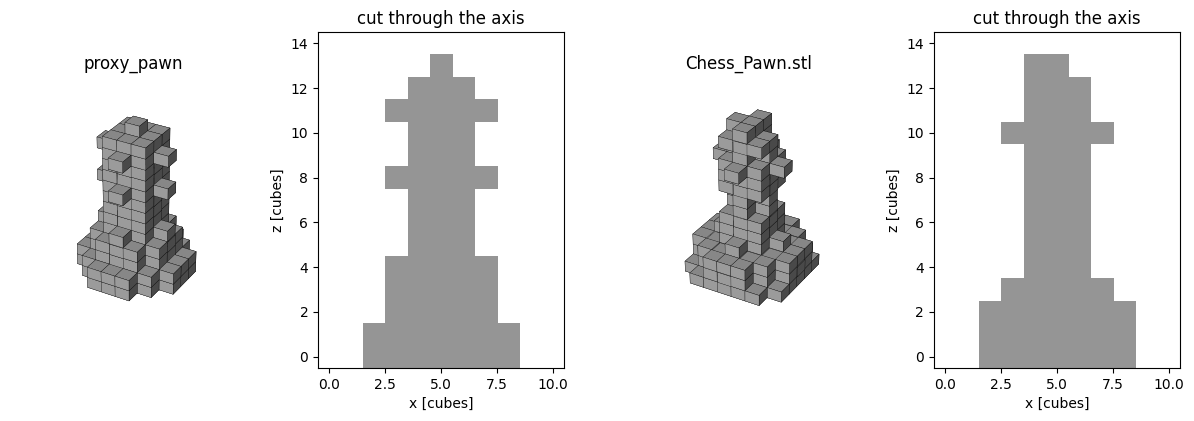

In [11]:
fig = plt.figure(figsize=(12, 5))
for k, (name, block) in enumerate(blocks.items()):
    grid = statue_grid(block)

    ax = fig.add_subplot(1, 4, 2 * k + 1, projection="3d")
    ax.voxels(grid, facecolors=STATUE_COLOR, edgecolor="k", linewidth=0.2)
    ax.set_box_aspect(grid.shape)
    ax.set_axis_off()
    ax.set_title(name)

    ax = fig.add_subplot(1, 4, 2 * k + 2)
    middle = grid[:, grid.shape[1] // 2, :]
    ax.imshow(middle.T, origin="lower", cmap="Greys", vmin=0, vmax=2)
    ax.set_title("cut through the axis")
    ax.set_xlabel("x [cubes]")
    ax.set_ylabel("z [cubes]")
fig.tight_layout()
plt.show()

In [12]:
from scipy import ndimage
grid = statue_grid(voxels)
print("holes inside:", (ndimage.binary_fill_holes(grid) & ~grid).sum())

holes inside: 0


**What we see:** the two pawns have almost the same number of cubes (210 and 208), and both show a wide base, a narrow body, a collar and a head. They differ in the details. The model's base is taller (3 layers instead of 2), its body is straighter, and it has only one collar, at layer 10. Its head is hardly wider than the neck, while the proxy has a clear head at layer 11 and a pointed top. The cut through the axis is solid, with no holes or missing cubes inside. So the inside test worked even though the model is not watertight (its 3 parts touch). This only checks the middle slice, though. Also we check we see no holes present .

### 3.6 `voxelize`
`voxelize` does 3.1 to 3.4 in one call, straight from the file. This is the function the rest of the project will use in place of `proxy_pawn`. It has to give exactly the block we built step by step.

In [13]:
pawn_voxels = voxelize(MODELS / "Chess_Pawn.stl", STATUE_HEIGHT)
assert np.array_equal(pawn_voxels.centers, voxels.centers)
assert np.array_equal(pawn_voxels.is_statue, voxels.is_statue)
print(f"voxelize gives the same block: {pawn_voxels.is_statue.sum()} statue cubes of {len(pawn_voxels.centers)}")

voxelize gives the same block: 208 statue cubes of 1815


**Result:** both asserts pass, so `voxelize` gives exactly the same block as the steps 3.1 to 3.4: the same 1815 cube centres and the same 208 statue cubes. From here on, one call to `voxelize(path, STATUE_HEIGHT)` replaces `proxy_pawn`, and any other model in `models/` can be loaded the same way.

## 4. Cube size and detail

The size of the cubes decides how much of the statue survives. Big cubes make few cubes: Swift draws them fast and the carving is short, but the statue comes out rough. Small cubes keep more detail, but the number of cubes grows like $1/a^3$: half the size, eight times the cubes.

`CUBE_SIZE` = 3 cm was chosen in notebook 00 from the step times of Swift. Here we measure what that choice costs in detail, by voxelizing the same pawn with cubes from 6 cm down to 1.5 cm. Each size divides the 0.42 m of the statue exactly, so every block has a whole number of layers.

In [14]:
# Cube sizes to compare, in metres; each divides STATUE_HEIGHT = 0.42 m exactly
SIZES = [0.06, 0.042, 0.03, 0.021, 0.015]

grids = {size: inside(pawn, grid_centers(pawn, size)) for size in SIZES}
pd.DataFrame.from_dict({f"{size * 100:g} cm": {"layers": grid.shape[2], "statue cubes": int(grid.sum())}
                        for size, grid in grids.items()}, orient="index")

,layers,statue cubes
6 cm,7,19
4.2 cm,10,81
3 cm,14,208
2.1 cm,20,624
1.5 cm,28,1697


**Result:** the number of cubes follows the $1/a^3$ rule. Halving the size multiplies the statue cubes by about 8: from 208 to 1697 going from 3 cm to 1.5 cm (×8.2), and from 81 to 624 going from 4.2 cm to 2.1 cm (×7.7). At 6 cm the pawn is only 19 cubes, so the rule holds less well: with so few cubes, a single layer more or less changes the count a lot. At our 3 cm, the statue has 208 cubes, 11 times more than at 6 cm but 8 times fewer than at 1.5 cm.

### 4.1 The shape of the pawn

To see what each size loses, we need the shape of the pawn itself to compare with. We take a very fine grid of **5 mm cubes** as the reference: at that size the cubes follow the surface of the model closely, and its volume should match the volume of the mesh.

In [15]:
# A fine grid of 5 mm cubes stands in for the exact shape of the pawn
REFERENCE = 0.005
fine_centers = grid_centers(pawn, REFERENCE)
fine = inside(pawn, fine_centers)
print(f"Reference: {fine.sum()} cubes of 5 mm, volume {fine.sum() * REFERENCE**3 * 1e3:.2f} L "
      f"(the mesh: {pawn.volume * 1e3:.2f} L)")

Reference: 45186 cubes of 5 mm, volume 5.65 L (the mesh: 5.67 L)


**Result:** the 5 mm grid has 45 186 statue cubes with a volume of 5.65 L, only 0.4 % below the 5.67 L of the mesh. The fine grid follows the model closely enough to serve as the exact shape of the pawn. 

Each size cut through the axis of the table, with the outline of the reference in red. Inside the red line is the pawn; grey cubes outside it are marble that the statue keeps, and white inside it is pawn that the cubes lose.

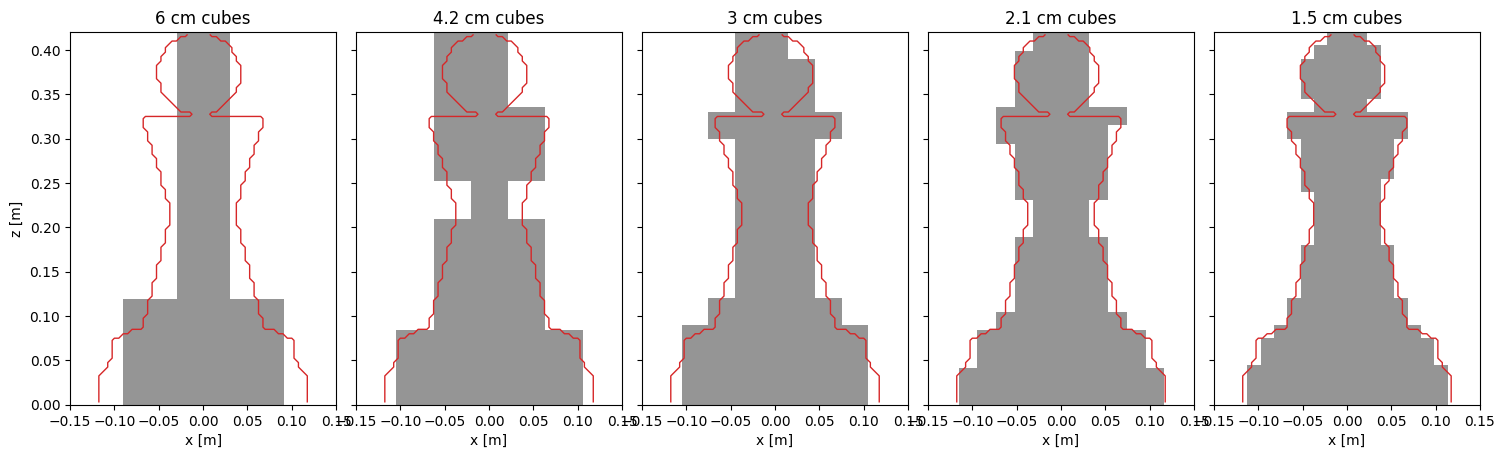

In [16]:
fig, axes = plt.subplots(1, len(SIZES), figsize=(3 * len(SIZES), 4.5), sharex=True, sharey=True)
fine_x, fine_z = fine_centers[:, 0, 0, 0], fine_centers[0, 0, :, 2]
fine_cut = fine[:, fine.shape[1] // 2, :]
for ax, (size, grid) in zip(axes, grids.items()):
    half = grid.shape[0] * size / 2
    ax.imshow(grid[:, grid.shape[1] // 2, :].T, origin="lower", cmap="Greys", vmin=0, vmax=2,
              extent=[-half, half, 0, grid.shape[2] * size])
    ax.contour(fine_x, fine_z, fine_cut.T.astype(float), levels=[0.5], colors="tab:red", linewidths=1)
    ax.set_title(f"{size * 100:g} cm cubes")
    ax.set_xlabel("x [m]")
axes[0].set_ylabel("z [m]")
fig.tight_layout()
plt.show()

**What we see:** the red line is the outline of the 5 mm reference, and the grey cubes are what each size keeps.
- **6 cm:** only a base and a straight post are left. The body's curve, the collar and the head are all gone.
- **4.2 cm:** the collar and the head merge into one block, and the body has a sharp pinch that the real pawn doesn't have.
- **3 cm (our size):** every part is there: the wide base, the tapered body, the collar and the head. But the head is a square block sitting straight on the collar, without the thin neck between them.
- **2.1 cm and 1.5 cm:** the neck comes back and the head starts to look round. At 1.5 cm the cubes follow the red line closely.

Because a cube is kept when its **centre** is inside, cubes can stick out past the line or fall short of it by up to half a cube. That's why the steps cross the red line on both sides. At 3 cm the pawn is still recognisable; the fine details (neck, round head) need about 2 cm or less.

### 4.2 How much is kept

Two numbers say how close the cubes are to the pawn, both as a share of the volume of the pawn $V$:

$$\text{kept} = \frac{V(\text{pawn} \cap \text{cubes})}{V}, \qquad \text{extra} = \frac{V(\text{cubes outside the pawn})}{V}$$

*Kept* is the part of the pawn that is inside statue cubes; the rest is lost, carved away with the marble. *Extra* is the marble that stays on the statue because it sits in a statue cube. Both are measured with the 5 mm reference: each fine cube stands for its small volume, and we look up which big cube it falls in.

The table also counts the cubes Swift has to draw: the whole block (statue and marble), and what is left after `drop_interior` (section 5).

In [17]:
def in_statue(grid: np.ndarray, size: float, points: np.ndarray) -> np.ndarray:
    """True for the points that fall in a statue cube of a grid laid by `grid_centers`."""
    n_x, n_y, n_z = grid.shape
    i = np.round(points[:, 0] / size).astype(int) + (n_x - 1) // 2
    j = np.round(points[:, 1] / size).astype(int) + (n_y - 1) // 2
    k = np.floor(points[:, 2] / size).astype(int)
    on_grid = (i >= 0) & (i < n_x) & (j >= 0) & (j < n_y) & (k >= 0) & (k < n_z)
    hit = np.zeros(len(points), dtype=bool)
    hit[on_grid] = grid[i[on_grid], j[on_grid], k[on_grid]]
    return hit


# The fine centres, moved by a micrometre so none falls exactly on the side of a big cube
points = fine_centers.reshape(-1, 3) + 1e-6
in_pawn = fine.ravel()

rows = {}
for size, grid in grids.items():
    in_cubes = in_statue(grid, size, points)
    block = from_grid(grid, size)
    rows[f"{size * 100:g} cm"] = {
        "statue cubes": int(grid.sum()),
        "cubes in Swift": len(block.centers),
        "after drop_interior": len(drop_interior(block).centers),
        "pawn kept [%]": round(100 * (in_pawn & in_cubes).sum() / in_pawn.sum(), 1),
        "extra [%]": round(100 * (~in_pawn & in_cubes).sum() / in_pawn.sum(), 1),
    }
detail = pd.DataFrame.from_dict(rows, orient="index")
detail

,statue cubes,cubes in Swift,after drop_interior,pawn kept [%],extra [%]
6 cm,19,392,390,65.8,6.8
4.2 cm,81,891,868,87.5,19.9
3 cm,208,1815,1738,87.3,12.1
2.1 cm,624,4725,4411,92.2,11.0
1.5 cm,1697,10469,9407,94.7,6.7


**Result:** smaller cubes keep more of the pawn, but the gain slows down quickly while the cost grows fast.
- **6 cm** keeps only 66 % of the pawn, so a third of the statue is carved away.
- **4.2 cm and 3 cm** keep the same share (87 %), but 3 cm fits much better: 12 % extra marble instead of 20 %.
- **2.1 cm** keeps 92 % but needs 2.6 times the cubes in Swift (4725 instead of 1815). **1.5 cm** keeps 95 % for 5.8 times the cubes.

So 3 cm is a good compromise: going smaller gains at most 7 points of the pawn, but multiplies Swift's work by 3 to 6.

`drop_interior` saves little: 77 cubes at 3 cm (4 %), and about 10 % at 1.5 cm. It only removes hidden **statue** cubes, and most of the block is marble.

## 5. Scene in Swift

The pawn as `voxelize` sees it, on the table: the model, scaled and placed, drawn see-through. The statue cubes fill it one layer at a time, and then the marble closes the block the robot carves.


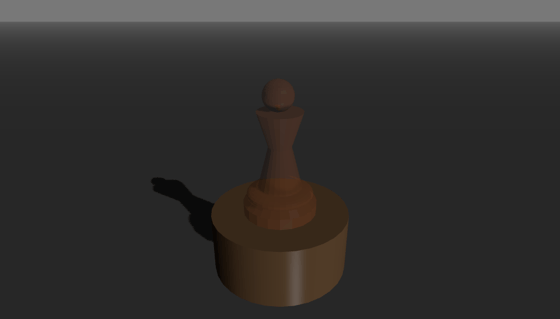

In [18]:
GIF = RECORDINGS / "02_voxelization_block.gif"
# Close to the table and a bit above the block
CAMERA = ([0.75, -1.05, 0.85], [0.75, 0.0, 0.34])

if RECORD or not GIF.exists():
    cell = Cell()
    model = (MODELS / "Chess_Pawn.stl").resolve()

    # The model as voxelize places it: scaled to STATUE_HEIGHT, centred on the axis, standing on the table
    scale = STATUE_HEIGHT / pawn_file.extents[2]
    low, high = pawn_file.bounds * scale
    offset = [-(low[0] + high[0]) / 2, -(low[1] + high[1]) / 2, -low[2]]

    env = swift.Swift()
    env.launch(realtime=True, browser=None, axes=False)
    add_table(env, cell)
    env.add(sg.Mesh(str(model), scale=[scale] * 3, pose=cell.block_pose(0.0) * sm.SE3(offset),
                    color=[*STATUE[:3], 0.35]))
    env.step(0.05)

    layers = np.round(pawn_voxels.centers[:, 2] / pawn_voxels.size - 0.5).astype(int)
    with recording(env, GIF, camera=CAMERA):
        for _ in range(10):
            env.step(0.05)
        # The statue cubes, one layer at a time
        for k in range(layers.max() + 1):
            for p in pawn_voxels.centers[pawn_voxels.is_statue & (layers == k)]:
                env.add(sg.Cuboid(scale=[pawn_voxels.size] * 3, pose=cell.block_pose(0.0) * sm.SE3(p), color=STATUE))
            for _ in range(3):
                env.step(0.05)
        for _ in range(10):
            env.step(0.05)
        # Then the marble around them
        for k in range(layers.max() + 1):
            for p in pawn_voxels.centers[~pawn_voxels.is_statue & (layers == k)]:
                env.add(sg.Cuboid(scale=[pawn_voxels.size] * 3, pose=cell.block_pose(0.0) * sm.SE3(p), color=MARBLE))
            env.step(0.05)
        for _ in range(15):
            env.step(0.05)
    env.close()

show_gif(GIF)